# Разработка ML-модели

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from google.colab import drive
drive.mount('/content/drive')

path = "/content/drive/MyDrive/eduai-audit/data/"
df = pd.read_csv(path + "studentInfo.csv", na_values=["?"])

df.head()

Mounted at /content/drive


,code_module,code_presentation,id_student,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,disability,final_result
0,AAA,2013J,11391,M,East Anglian Region,HE Qualification,90-100%,55<=,0,240,N,Pass
1,AAA,2013J,28400,F,Scotland,HE Qualification,20-30%,35-55,0,60,N,Pass
2,AAA,2013J,30268,F,North Western Region,A Level or Equivalent,30-40%,35-55,0,60,Y,Withdrawn
3,AAA,2013J,31604,F,South East Region,A Level or Equivalent,50-60%,35-55,0,60,N,Pass
4,AAA,2013J,32885,F,West Midlands Region,Lower Than A Level,50-60%,0-35,0,60,N,Pass


In [2]:
df["dropout"] = (df["final_result"] == "Withdrawn").astype(int)
df["dropout"].value_counts(normalize=True) * 100

,proportion
dropout,
0,68.839935
1,31.160065


In [3]:
features = [
    "code_module",
    "code_presentation",
    "gender",
    "region",
    "highest_education",
    "imd_band",
    "age_band",
    "num_of_prev_attempts",
    "studied_credits",
    "disability"
]

X = df[features]
y = df["dropout"]

#Мы специально не включаем final_result во избежание data leakage

In [4]:
print('Features:', X.shape)
print('Target:', y.shape)

X.head()

Features: (32593, 10)
Target: (32593,)


,code_module,code_presentation,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,disability
0,AAA,2013J,M,East Anglian Region,HE Qualification,90-100%,55<=,0,240,N
1,AAA,2013J,F,Scotland,HE Qualification,20-30%,35-55,0,60,N
2,AAA,2013J,F,North Western Region,A Level or Equivalent,30-40%,35-55,0,60,Y
3,AAA,2013J,F,South East Region,A Level or Equivalent,50-60%,35-55,0,60,N
4,AAA,2013J,F,West Midlands Region,Lower Than A Level,50-60%,0-35,0,60,N


In [5]:
from sklearn.model_selection import GroupShuffleSplit

splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(splitter.split(X, y, groups=df['id_student']))

x_train = X.iloc[train_idx]
x_test = X.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

In [6]:
categorical_features = [
    "code_module",
    "code_presentation",
    "gender",
    "region",
    "highest_education",
    "imd_band",
    "age_band",
    "disability"
]

numerical_features = [
    "num_of_prev_attempts",
    "studied_credits"
]

In [7]:
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

In [8]:
cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(
        strategy='constant',
        fill_value='Unknown'
    )),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

preprocessor = ColumnTransformer([
    ('cat', cat_pipeline, categorical_features),
    ('num', num_pipeline, numerical_features)
])

In [9]:
model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000))
])

model.fit(x_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='Unknown',
                                                                                 strategy='constant')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['code_module',
                                                   'code_presentation',
                                                   'gender', 'region',
                                                   'highest_education',
                                                   'imd_band', 'age_band',
                                                   'disability']),
                                                 ('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['num_of_prev_attempts',
                                                   'studied_credits'])])),
                ('classifier', LogisticRegression(max_iter=1000))])

In [10]:
model.named_steps["classifier"].n_iter_

array([29], dtype=int32)

In [11]:
y_pred = model.predict(x_test)
y_prob = model.predict_proba(x_test)[:, 1]

In [12]:
print("Predictions:", y_pred[:10])
print("Probabilities:", y_prob[:10])
print("Actual values:", y_test.iloc[:10].values)

Predictions: [0 0 0 0 0 0 0 0 0 0]
Probabilities: [0.29310623 0.07449344 0.14312229 0.14381246 0.24225519 0.15747173
 0.21575099 0.11175492 0.09935304 0.19687961]
Actual values: [0 0 0 0 0 1 0 0 0 0]


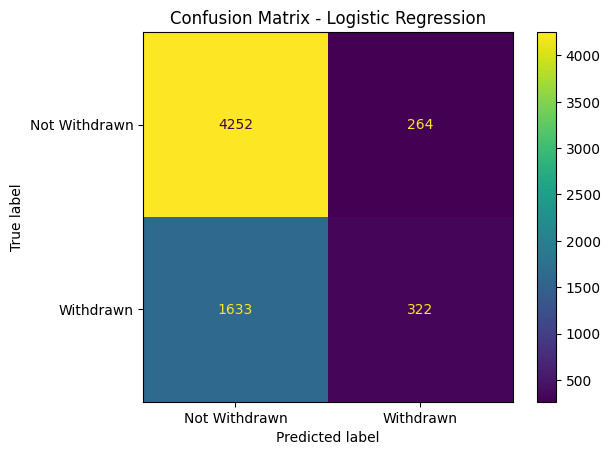

In [13]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Not Withdrawn', 'Withdrawn']
)

disp.plot()
plt.title('Confusion Matrix - Logistic Regression')
plt.show()

Из 1955 реальных случаев Withdrawn наша модель обнаружила только 322:

4252 — True Negative (TN). Модель правильно определила, что студент не прекратит обучение.



264 — False Positive (FP). Модель предсказала прекращение обучения, но студент его не прекратил.



1633 — False Negative (FN). Модель предсказала, что студент не прекратит обучение, хотя в действительности он прекратил.



322 — True Positive (TP). Модель правильно обнаружила прекращение обучения.

Что произойдёт, если мы снизим порог классификации с 50% до 30%?

In [14]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

print("Accuracy (доля всех правильных прогнозов):", accuracy_score(y_test, y_pred))
print("Precision (доля верных предупреждений):", precision_score(y_test, y_pred))
print("Recall (доля обнаруженных случаев прекращения обучения):", recall_score(y_test, y_pred))
print("F1 (баланс Precision и Recall):", f1_score(y_test, y_pred))
print("ROC-AUC (качество различения двух классов при различных порогах):", roc_auc_score(y_test, y_prob))


Accuracy (доля всех правильных прогнозов): 0.7068459279864009
Precision (доля верных предупреждений): 0.5494880546075085
Recall (доля обнаруженных случаев прекращения обучения): 0.16470588235294117
F1 (баланс Precision и Recall): 0.2534435261707989
ROC-AUC (качество различения двух классов при различных порогах): 0.6792516066772534


ROC-AUC показывает, насколько хорошо модель ранжирует студентов по риску.
Например, случайно выбираем:
- Одного студента, который действительно прекратил обучение.
- Одного студента, который не прекратил обучение.


ROC-AUC = 0,679 означает, что примерно в 67,9% таких пар модель присвоит более высокий риск студенту, который действительно прекратил обучение (с учётом половины веса совпадающих оценок).

In [15]:
thresholds = [0.2, 0.3, 0.4, 0.5]

for threshold in thresholds:
  y_pred_new = (y_prob >= threshold).astype(int)

  preсision = precision_score(y_test, y_pred_new, zero_division=0)
  recall = recall_score(y_test, y_pred_new)
  f1 = f1_score(y_test, y_pred_new)

  print(f"Threshold: {threshold}")
  print(f"Precision: {preсision:.3f}")
  print(f"Recall: {recall:.3f}")
  print(f"F1: {f1:.3f}")
  print("----------------------")

Threshold: 0.2
Precision: 0.344
Recall: 0.909
F1: 0.499
----------------------
Threshold: 0.3
Precision: 0.416
Recall: 0.678
F1: 0.515
----------------------
Threshold: 0.4
Precision: 0.504
Recall: 0.380
F1: 0.433
----------------------
Threshold: 0.5
Precision: 0.549
Recall: 0.165
F1: 0.253
----------------------


Среди четырёх исследованных порогов 0,3 даёт максимальный F1-score — 0,515.

У нашей модели ROC-AUC = 0,679 независимо от того, какой порог из четырёх мы используем.

Однако Recall меняется от 16,5% до 90,9%.

Нужно также исследовать, как параметры принятия решений влияют на количество пропущенных студентов и ложных предупреждений.

In [16]:
#Cколько студентов получает предупреждение при каждом пороге?

for threshold in thresholds:
    y_pred_new = (y_prob >= threshold).astype(int)

    alerts = y_pred_new.sum()

    print(f"Threshold: {threshold}")
    print(f"Students flagged: {alerts}")
    print(f"Alert rate: {alerts / len(y_pred_new) * 100:.1f}%")
    print("----------------------")

Threshold: 0.2
Students flagged: 5175
Alert rate: 80.0%
----------------------
Threshold: 0.3
Students flagged: 3186
Alert rate: 49.2%
----------------------
Threshold: 0.4
Students flagged: 1473
Alert rate: 22.8%
----------------------
Threshold: 0.5
Students flagged: 586
Alert rate: 9.1%
----------------------


При пороге 0,2 университет получил бы 5175 предупреждений на 6471 запись.

При пороге 0,5 предупреждений всего 586, но модель пропускает около 83,5% реальных случаев

При пороге 0,3 получаем 3186 предупреждений и Recall 67,8%.

# Fairness Audit

In [17]:
audit_df = x_test.copy()
audit_df['actual'] = y_test.to_numpy()
audit_df['predicted'] = (y_prob >= 0.3).astype(int)
audit_df['probability'] = y_prob
audit_df.head()

,code_module,code_presentation,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,disability,actual,predicted,probability
0,AAA,2013J,M,East Anglian Region,HE Qualification,90-100%,55<=,0,240,N,0,0,0.293106
5,AAA,2013J,M,Wales,A Level or Equivalent,80-90%,35-55,0,60,N,0,0,0.074493
8,AAA,2013J,F,East Anglian Region,A Level or Equivalent,70-80%,0-35,0,90,N,0,0,0.143122
14,AAA,2013J,M,Scotland,Lower Than A Level,40-50%,35-55,0,60,N,0,0,0.143812
18,AAA,2013J,M,East Anglian Region,A Level or Equivalent,10-20,35-55,0,150,N,0,0,0.242255


In [18]:
#Одинаков ли Recall для студентов из районов с разным уровнем депривации?

recall_by_imd = (
    audit_df.dropna(subset=['imd_band'])
    .groupby('imd_band')
    .apply(
      lambda group: recall_score(
        group['actual'],
        group['predicted'],
        zero_division=0
    ),
      include_groups=False
    )
)

print(recall_by_imd)

imd_band
0-10%      0.811024
10-20      0.801587
20-30%     0.794239
30-40%     0.725888
40-50%     0.684211
50-60%     0.583784
60-70%     0.629412
70-80%     0.558621
80-90%     0.537879
90-100%    0.442748
dtype: float64


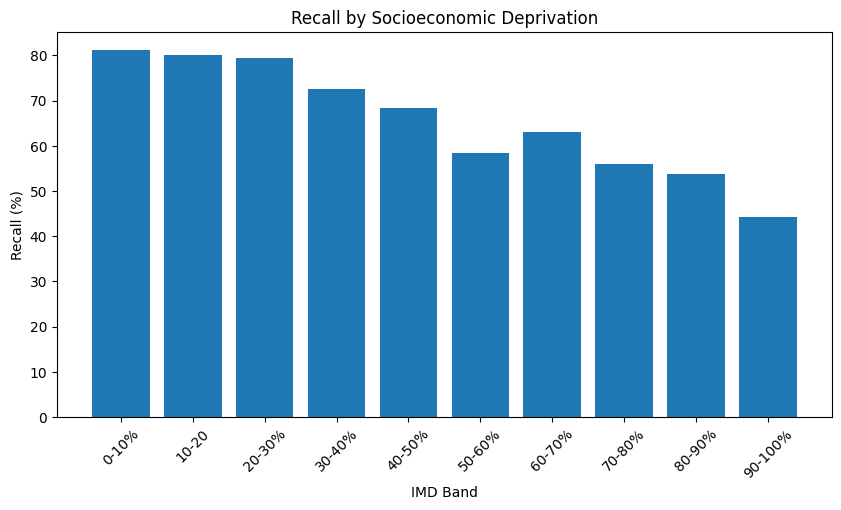

In [19]:
recall_by_imd = recall_by_imd.sort_index()

plt.figure(figsize=(10, 5))

plt.bar(
    recall_by_imd.index,
    recall_by_imd.values * 100
)

plt.xlabel("IMD Band")
plt.ylabel("Recall (%)")
plt.title("Recall by Socioeconomic Deprivation")
plt.xticks(rotation=45)
plt.show()

Модель гораздо лучше обнаруживает прекращение обучения среди студентов из более депривированных районов.

НО: Модель может чаще находить реальные случаи Withdrawn среди студентов из депривированных районов, но одновременно гораздо чаще выдавать им ложные предупреждения.

Проверка FPR: Среди студентов, которые не прекратили обучение, какую долю модель ошибочно отнесла к группе риска?

In [20]:
def calculate_fpr(group):
  tn, fp, fn, tp = confusion_matrix(
      group['actual'],
      group['predicted'],
      labels=[0, 1]
  ).ravel()

  return fp / (fp + tn ) if (fp + tn) > 0 else np.nan

fpr_by_imd = (
    audit_df.dropna(subset=['imd_band'])
    .groupby('imd_band')
    .apply(calculate_fpr, include_groups=False)
)

print(fpr_by_imd)

imd_band
0-10%      0.603604
10-20      0.534335
20-30%     0.562500
30-40%     0.428875
40-50%     0.465812
50-60%     0.302428
60-70%     0.368421
70-80%     0.314904
80-90%     0.320755
90-100%    0.277500
dtype: float64


Получается, модель имеет две особенности:

- В более депривированных группах она обнаруживает больше реальных случаев прекращения обучения.
- Но одновременно она выдаёт значительно больше ложных предупреждений.

Если Recall (TPR) и FPR сильно отличаются - проблема Equalized Odds (критерий алгоритмической справедливости, требующий одинаковых TPR и FPR между сравниваемыми группами).

Посчитаем количество реальных случаев Withdrawn, количество ложных предупреждений и размеры групп.

In [21]:
group_stats = audit_df.groupby('imd_band').agg(
    n=('actual', 'size'),
    actual_withdrawn=('actual', 'sum'),
    predicted_witdrawn=('predicted', 'sum')
)

print(group_stats)

            n  actual_withdrawn  predicted_witdrawn
imd_band                                           
0-10%     698               254                 474
10-20     718               252                 451
20-30%    691               243                 445
30-40%    668               197                 345
40-50%    677               209                 361
50-60%    638               185                 245
60-70%    569               170                 254
70-80%    561               145                 212
80-90%    503               132                 190
90-100%   531               131                 169


При пороге 0,3 модель значительно чаще классифицирует студентов из депривированных районов как находящихся в группе риска — независимо от того, прекратят они обучение или нет.

In [22]:
group_performance = audit_df.dropna(subset=["imd_band"]).groupby("imd_band").apply(
    lambda group: pd.Series({
        "accuracy": accuracy_score(group["actual"], group["predicted"]),
        "precision": precision_score(
            group["actual"], group["predicted"], zero_division=0
        )
    }),
    include_groups=False
)

print(group_performance.round(3))

          accuracy  precision
imd_band                     
0-10%        0.547      0.435
10-20        0.584      0.448
20-30%       0.563      0.434
30-40%       0.617      0.414
40-50%       0.581      0.396
50-60%       0.665      0.441
60-70%       0.631      0.421
70-80%       0.652      0.382
80-90%       0.642      0.374
90-100%      0.653      0.343


Мы обнаружили существенные различия в работе модели:

- В наиболее депривированных группах модель чаще обнаруживает реальные случаи прекращения обучения.
- Но там же она гораздо чаще выдаёт ложные предупреждения среди тех, кто не прекратил обучение.
- В менее депривированных группах Accuracy выше, но Recall и Precision ниже.

Вывод: Модель демонстрирует различия в частоте ошибок между социально-экономическими группами, причём повышение Recall сопровождается повышением FPR.

In [23]:
#Рассчитаем 95%-е доверительные интервалы для Recall и FPR по каждой категории IMD c помощью Wilson confidence interval.

from statsmodels.stats.proportion import proportion_confint

def calculate_recall_ci(group):
    tn, fp, fn, tp = confusion_matrix(
        group["actual"],
        group["predicted"],
        labels=[0, 1]
    ).ravel()

    total_positive = tp + fn

    if total_positive == 0:
      return np.nan, np.nan, np.nan

    recall = tp / total_positive

    ci_low, ci_high = proportion_confint(
        count=tp,
        nobs=total_positive,
        alpha=0.05,
        method='wilson'
    )

    return recall, ci_low, ci_high

def calculate_fpr_ci(group):
  tn, fp, fn, tp = confusion_matrix(
        group["actual"],
        group["predicted"],
        labels=[0, 1]
    ).ravel()

  total_negative = fp + tn

  if total_negative == 0:
    return np.nan, np.nan, np.nan

  fpr = fp / total_negative

  ci_low, ci_high = proportion_confint(
      count=fp,
      nobs=fp+tn,
      alpha=0.05,
      method='wilson'
  )

  return fpr, ci_low, ci_high


In [24]:
recall_ci = {}

for imd, group in audit_df.dropna(subset=["imd_band"]).groupby("imd_band"):
    recall_ci[imd] = calculate_recall_ci(group)

recall_ci_df = pd.DataFrame.from_dict(
    recall_ci,
    orient="index",
    columns=["recall", "ci_low", "ci_high"]
)

print(recall_ci_df.round(3))

         recall  ci_low  ci_high
0-10%     0.811   0.758    0.854
10-20     0.802   0.748    0.846
20-30%    0.794   0.739    0.840
30-40%    0.726   0.660    0.783
40-50%    0.684   0.618    0.743
50-60%    0.584   0.512    0.652
60-70%    0.629   0.555    0.698
70-80%    0.559   0.477    0.637
80-90%    0.538   0.453    0.621
90-100%   0.443   0.361    0.528


Модель гораздо чаще обнаруживает реальные случаи прекращения обучения среди студентов из наиболее депривированных районов.

In [25]:
fpr_ci = {}

for imd, group in audit_df.dropna(subset=["imd_band"]).groupby("imd_band"):
    fpr_ci[imd] = calculate_fpr_ci(group)

fpr_ci_df = pd.DataFrame.from_dict(
    fpr_ci,
    orient="index",
    columns=["fpr", "ci_low", "ci_high"]
)

print(fpr_ci_df.round(3))

           fpr  ci_low  ci_high
0-10%    0.604   0.557    0.648
10-20    0.534   0.489    0.579
20-30%   0.562   0.516    0.608
30-40%   0.429   0.385    0.474
40-50%   0.466   0.421    0.511
50-60%   0.302   0.262    0.346
60-70%   0.368   0.323    0.417
70-80%   0.315   0.272    0.361
80-90%   0.321   0.275    0.370
90-100%  0.278   0.236    0.323


Модель значительно чаще ошибочно классифицирует студентов из наиболее депривированных районов как находящихся в группе риска.

Выводы:

- различия между наиболее и наименее депривированными группами настолько велики, что их 95%-е доверительные интервалы даже не пересекаются.
- потенциальное нарушение критерия Equalized Odds

Насколько устойчивы различия, если учитывать случайность выборки и повторные наблюдения одних и тех же студентов?

Используем Cluster Bootstrap.

В OULAD один студент может проходить несколько курсов, а значит, иметь несколько записей. Мы же хотим выбирать целых студентов вместе со всеми их записями. Этот метод учитывает зависимость.

In [26]:
audit_df['id_student'] = df.iloc[test_idx]['id_student'].to_numpy()
audit_df[["id_student", "imd_band", "actual", "predicted"]].head()

,id_student,imd_band,actual,predicted
0,11391,90-100%,0,0
5,38053,80-90%,0,0
8,52130,70-80%,0,0
14,63400,40-50%,0,0
18,74372,10-20,0,0


In [27]:
def calculate_metrics(group):
    tn, fp, fn, tp = confusion_matrix(
        group["actual"],
        group["predicted"],
        labels=[0, 1]
    ).ravel()

    recall = tp / (tp + fn) if (tp + fn) > 0 else np.nan
    fpr = fp / (fp + tn) if (fp + tn) > 0 else np.nan

    return recall, fpr

def calculate_difference(data):
    group_a = data[data["imd_band"] == "0-10%"]
    group_b = data[data["imd_band"] == "90-100%"]

    recall_a, fpr_a = calculate_metrics(group_a)
    recall_b, fpr_b = calculate_metrics(group_b)

    return recall_a - recall_b, fpr_a - fpr_b

In [28]:
#Cluster Bootstrap

student_groups = {
    student_id: group
    for student_id, group in audit_df.groupby("id_student")
}

student_ids = np.array(list(student_groups.keys()))

rng = np.random.default_rng(42)

n_bootstrap = 1000
bootstrap_results = []

for i in range(n_bootstrap):

    sampled_ids = rng.choice(
        student_ids,
        size=len(student_ids),
        replace=True
    )

    sample = pd.concat(
        [student_groups[student_id] for student_id in sampled_ids],
        ignore_index=True
    )

    diff_recall, diff_fpr = calculate_difference(sample)

    bootstrap_results.append([diff_recall, diff_fpr])

In [32]:
bootstrap_results = np.array(bootstrap_results)

ci_recall = np.nanpercentile(
    bootstrap_results[:, 0],
    [2.5, 97.5]
)

ci_fpr = np.nanpercentile(
    bootstrap_results[:, 1],
    [2.5, 97.5]
)

diff_recall, diff_fpr = calculate_difference(audit_df)

print("Recall difference:", diff_recall)
print("Recall 95% CI:", ci_recall)

print("FPR difference:", diff_fpr)
print("FPR 95% CI:", ci_fpr)

print("Valid Recall samples:",
      np.isfinite(bootstrap_results[:, 0]).sum())

print("Valid FPR samples:",
      np.isfinite(bootstrap_results[:, 1]).sum())

Recall difference: 0.36827553044419065
Recall 95% CI: [0.26423316 0.46743413]
FPR difference: 0.32610360360360363
FPR 95% CI: [0.25916405 0.38730573]
Valid Recall samples: 1000
Valid FPR samples: 1000


Данные дают достаточно убедительные статистические свидетельства различия в способности модели обнаруживать реальные случаи Withdrawn между крайними группами IMD.

Модель неодинаково классифицирует студентов из разных социально-экономических групп:

- В наиболее депривированных районах она чаще обнаруживает реальные случаи прекращения обучения, но одновременно чаще ошибочно выдаёт предупреждения студентам, которые не прекратят обучение.

- Такие различия свидетельствуют о несоответствии оценок TPR и FPR между крайними группами и вызывают вопросы с точки зрения критерия Equalized Odds.

#Calibration Audit

In [33]:
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss

prob_true, prob_pred = calibration_curve(
    y_test,
    y_prob,
    n_bins=10,
    strategy='uniform'
)

brier = brier_score_loss(y_test, y_prob)
print("Brier Score:", round(brier, 4))

Brier Score: 0.1936


In [34]:
baseline_prob = y_train.mean()

baseline_predictions = np.full(
    len(y_test),
    baseline_prob
)

baseline_brier = brier_score_loss(
    y_test,
    baseline_predictions
)

print("Baseline Brier Score:", round(baseline_brier, 4))
print("Our Model Brier Score:", round(brier, 4))

Baseline Brier Score: 0.211
Our Model Brier Score: 0.1936


Text(0.5, 1.0, 'Calibration Curve — Logistic Regression')

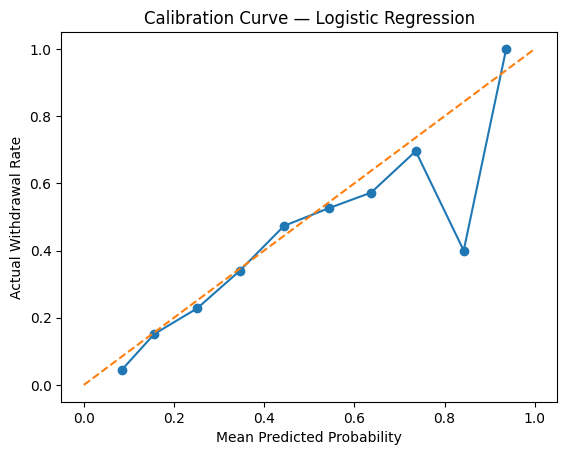

In [35]:
plt.plot(
    prob_pred,
    prob_true,
    marker="o",
    label="Logistic Regression"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect Calibration"
)

plt.xlabel("Mean Predicted Probability")
plt.ylabel("Actual Withdrawal Rate")
plt.title("Calibration Curve — Logistic Regression")

In [37]:
calibration_df = pd.DataFrame({
    "actual": y_test.to_numpy(),
    "probability": y_prob
})

calibration_df["prob_bin"] = pd.cut(
    calibration_df["probability"],
    bins=np.linspace(0, 1, 11),
    include_lowest=True
)

calibration_stats = calibration_df.groupby(
    "prob_bin", observed=False
).agg(
    n=("actual", "size"),
    actual_rate=("actual", "mean"),
    predicted_rate=("probability", "mean")
)

print(calibration_stats)

                  n  actual_rate  predicted_rate
prob_bin                                        
(-0.001, 0.1]   182     0.043956        0.083597
(0.1, 0.2]     1114     0.151706        0.156382
(0.2, 0.3]     1989     0.227753        0.251280
(0.3, 0.4]     1713     0.340339        0.346322
(0.4, 0.5]      887     0.473506        0.444186
(0.5, 0.6]      390     0.525641        0.542693
(0.6, 0.7]      138     0.572464        0.637220
(0.7, 0.8]       46     0.695652        0.736029
(0.8, 0.9]       10     0.400000        0.842459
(0.9, 1.0]        2     1.000000        0.936682


Logistic Regression демонстрирует сравнительно небольшие отклонения между прогнозируемыми вероятностями и фактическими частотами в наиболее многочисленных диапазонах.

In [38]:
group_calibration = audit_df.groupby("imd_band").agg(
    n=("actual", "size"),
    actual_rate=("actual", "mean"),
    predicted_rate=("probability", "mean")
)

group_calibration["difference"] = (
    group_calibration["predicted_rate"]
    - group_calibration["actual_rate"]
)

print(group_calibration.round(3))

            n  actual_rate  predicted_rate  difference
imd_band                                              
0-10%     698        0.364           0.365       0.001
10-20     718        0.351           0.355       0.004
20-30%    691        0.352           0.356       0.004
30-40%    668        0.295           0.319       0.024
40-50%    677        0.309           0.325       0.016
50-60%    638        0.290           0.280      -0.010
60-70%    569        0.299           0.291      -0.008
70-80%    561        0.258           0.277       0.018
80-90%    503        0.262           0.288       0.026
90-100%   531        0.247           0.258       0.011


Модель довольно точно оценивает общую частоту Withdrawn в группе, но при пороге 0,3 выдаёт предупреждения почти 68% наблюдений этой группы.

Хорошая калибровка средних вероятностей не гарантирует хорошую классификацию при конкретном пороге.

In [40]:
brier_by_imd = audit_df.groupby("imd_band").apply(
    lambda group: brier_score_loss(
        group["actual"],
        group["probability"]
    ),
    include_groups=False
)

print(brier_by_imd.round(4))

imd_band
0-10%      0.2145
10-20      0.2079
20-30%     0.2088
30-40%     0.1880
40-50%     0.1999
50-60%     0.1874
60-70%     0.1964
70-80%     0.1788
80-90%     0.1804
90-100%    0.1793
dtype: float64


Cредние вероятности в обеих группах довольно близки к фактическим частотам Withdrawn, но индивидуальные вероятностные прогнозы различаются по качеству.

In [41]:
def compare_brier(group):
    actual = group["actual"]
    probability = group["probability"]

    model_brier = brier_score_loss(actual, probability)

    group_rate = actual.mean()

    reference_brier = brier_score_loss(
        actual,
        np.full(len(actual), group_rate)
    )

    skill = 1 - model_brier / reference_brier

    return pd.Series({
        "model_brier": model_brier,
        "reference_brier": reference_brier,
        "brier_skill": skill
    })

brier_comparison = (
    audit_df.dropna(subset=["imd_band"])
    .groupby("imd_band")
    .apply(compare_brier, include_groups=False)
)

print(brier_comparison.round(4))

          model_brier  reference_brier  brier_skill
imd_band                                           
0-10%          0.2145           0.2315       0.0734
10-20          0.2079           0.2278       0.0873
20-30%         0.2088           0.2280       0.0842
30-40%         0.1880           0.2079       0.0959
40-50%         0.1999           0.2134       0.0633
50-60%         0.1874           0.2059       0.0898
60-70%         0.1964           0.2095       0.0624
70-80%         0.1788           0.1917       0.0671
80-90%         0.1804           0.1936       0.0679
90-100%        0.1793           0.1858       0.0353


Наиболее депривированная группа (0–10%) имеет худший абсолютный Brier Score — 0.2145, но её относительный выигрыш от модели больше, чем у наименее депривированной группы (90–100%).

Модель:

- Относительно постоянного прогноза улучшает вероятностные оценки во всех группах.
- В среднем довольно точно воспроизводит фактическую долю Withdrawn в каждой группе.
- Но при одном и том же пороге классификации значительно чаще выдаёт как верные, так и ложные предупреждения для наиболее депривированных студентов.

Калибровка относительно хорошая, но ошибки классификации распределяются неравномерно.